<div style="text-align: center; color:#000; font-family: Arial, sans-serif;
background: linear-gradient(135deg, #89c881 0%, #4caf50 100%);
padding: 20px; border-radius: 12px;
box-shadow: 0 4px 12px rgba(0,0,0,0.3); line-height: 1.6;">

<h2 style="margin:0 0 6px 0;">Series de Tiempo con Redes Neuronales</h2>
<h4 style="margin:0 0 4px 0;">Universidad Central</h4>
<h4 style="margin:0 0 4px 0;">Maestría en Analítica de Datos</h4>
<p style="margin:0 0 2px 0;"><strong>Docente:</strong> Wilson Sandoval Rodriguez</p>
<p style="margin:0;"><em>wsandovalr@ucentral.edu.co</em></p>
</div>

## Mapa del cuadernillo

Este cuadernillo cubre el flujo completo de modelado de series de tiempo
con redes neuronales aplicadas a datos de calidad del aire:

| # | Sección | Contenido |
|---|---------|-----------|
| 1 | Introducción | Motivación y contexto del Deep Learning en ST |
| 2 | Marco teórico | RNN, LSTM, GRU, tipos de problemas |
| 3 | Datos | Dataset de calidad del aire — Valencia, España |
| 4 | **EDA** | Valores faltantes, outliers, estacionalidad, correlaciones |
| 5 | División temporal | Train / Validación / Test sin solape |
| 6 | Escalado | MinMaxScaler sin fuga de información |
| 7 | Ventanas deslizantes | Construcción de secuencias para LSTM |
| 8 | LSTM univariado 1-paso | Modelo base con evaluación completa |
| 9 | LSTM multi-step | Horizonte de 24 a 120 horas |
| 10 | LSTM multivariado (N:1) | Todas las variables → predecir O₃ |
| **11** | **Comparativa de arquitecturas** | MLP, GRU, CNN-1D vs LSTM |
| 12 | Tabla comparativa | Todas las arquitecturas del estado del arte |
| 13 | Conclusiones | Interpretación y recomendaciones finales |

> **Variable objetivo:** Concentración de ozono (O₃) en µg/m³.
> **Frecuencia:** Horaria. **Período:** 2019-01-01 → 2023-12-31.

## 1. Introducción

![Series de Tiempo](https://github.com/Wilsonsr/Series-de-Tiempo/raw/main/assets/images/15_avanzados/red_neuronal_1.png)

Las **redes neuronales artificiales** son modelos computacionales inspirados en el
funcionamiento del cerebro humano. Están formadas por nodos (neuronas artificiales)
organizados en capas, donde cada nodo recibe información, la procesa y la transmite
a los nodos siguientes. Esta arquitectura permite aprender patrones complejos
directamente desde los datos, incluso cuando las relaciones no son lineales.

En el contexto de las **series de tiempo ambientales**, las redes neuronales son
especialmente valiosas porque:

- La calidad del aire tiene **patrones cíclicos** (hora del día, estación del año).
- Existen **dependencias temporales** entre contaminantes (e.g., NO₂ precede al O₃).
- Las relaciones entre variables son **no lineales** y difíciles de capturar con
  modelos estadísticos clásicos como ARIMA.

Este cuadernillo usa datos reales de contaminación atmosférica de Valencia (España)
para ilustrar el ciclo completo de modelado, desde el análisis exploratorio hasta
la comparación de múltiples arquitecturas de redes neuronales.

## 2. Marco Teórico

### 2.1 Redes Neuronales Recurrentes (RNN)

Las **RNN** son redes diseñadas para datos **secuenciales**, donde el orden importa.
A diferencia de una red feedforward (MLP), la RNN mantiene un **estado oculto**
que se actualiza en cada paso temporal, permitiéndole "recordar" el pasado.

![redes_neuronales.png](https://github.com/Wilsonsr/Series-de-Tiempo/raw/main/assets/images/15_avanzados/redes_neuronales.png)

**Limitación crítica:** Las RNN simples sufren el problema del
**gradiente desvaneciente** — durante el entrenamiento, los gradientes se hacen
tan pequeños que la red "olvida" información de pasos lejanos. Esto limita su
capacidad para capturar dependencias a largo plazo.

---

### 2.2 LSTM (Long Short-Term Memory)

Las **LSTM** fueron diseñadas específicamente para superar el problema del gradiente
desvaneciente. Su mecanismo central es la **celda de memoria** (cell state), que
puede mantener información relevante durante muchos pasos temporales.

![Diagrama LSTM](https://databasecamp.de/wp-content/uploads/lstm-architecture-1024x709.png)

Una celda LSTM tiene **tres puertas**:

| Puerta | Función | Activación |
|--------|---------|-----------|
| **Olvido** (Forget gate) | Decide qué parte del estado anterior eliminar | Sigmoide (0=olvidar, 1=mantener) |
| **Entrada** (Input gate) | Decide qué nueva información almacenar | Sigmoide + tanh |
| **Salida** (Output gate) | Decide qué parte del estado pasa como salida | Sigmoide + tanh |

```
h_t = output_gate ⊙ tanh(C_t)
C_t = forget_gate ⊙ C_{t-1} + input_gate ⊙ C̃_t
```

---

### 2.3 GRU (Gated Recurrent Unit)

La **GRU** es una versión simplificada de la LSTM con **dos puertas** en lugar de tres:

| Puerta | Función |
|--------|---------|
| **Actualización** (Update gate) | Controla cuánto del estado anterior conservar |
| **Reinicio** (Reset gate) | Controla qué parte del estado anterior usar para el nuevo candidato |

**Ventajas de GRU vs LSTM:**
- Menos parámetros → más rápida de entrenar.
- Rendimiento comparable en datasets de tamaño medio.
- Menos propensa a sobreajuste con pocos datos.

---

### 2.4 Tipos de problemas en series de tiempo

```
Entrada única → salida única (1:1)
  [x_t-24, ..., x_t] → [x_{t+1}]        Ejemplo: predecir O₃ de mañana

Múltiple → única (N:1)
  [x1_t, x2_t, ..., xN_t] → [y_{t+1}]  Ejemplo: PM2.5+NO2+CO → predecir O₃

Single-step:  predice 1 paso adelante
Multi-step:   predice H pasos adelante (horizonte H)
```

| Tipo | Entradas | Salida | Pasos futuros |
|------|----------|--------|---------------|
| 1:1 single-step | Una serie | 1 valor | 1 |
| 1:1 multi-step | Una serie | H valores | H |
| N:1 single-step | N series | 1 valor | 1 |
| N:1 multi-step | N series | H valores | H |
| N:M | N series | M series × H valores | H |

## 3. Instalación e importaciones

In [1]:
# Instalar dependencias si es necesario
# %pip install skforecast tensorflow scikit-learn plotly statsmodels seaborn

In [1]:
# ── Datos y matemáticas ──────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ── Visualización ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
import plotly.offline as poff
pio.templates.default = "plotly_white"
poff.init_notebook_mode(connected=True)

# ── Preprocesamiento ──────────────────────────────────────────────────────────
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                              r2_score)

# ── Deep Learning ─────────────────────────────────────────────────────────────
from keras.models import Sequential
from keras.layers import (Input, LSTM, GRU, Dense, Dropout,
                           Conv1D, GlobalAveragePooling1D, Flatten)
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

# ── Series de tiempo ──────────────────────────────────────────────────────────
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 4. Datos

Los datos provienen de la **Red de Vigilancia y Control de la Contaminación
Atmosférica** de la Generalitat Valenciana, estación
*46250054 – València Centre*.

| Característica | Valor |
|---|---|
| Período | 2019-01-01 → 2023-12-31 |
| Frecuencia | Horaria (1 registro/hora) |
| Total de registros | 43 824 horas |
| Variables | SO₂, CO, NO, NO₂, PM10, NOx, O₃, velocidad del viento, dirección del viento, PM2.5 |

> **Variable objetivo:** Ozono (O₃) en µg/m³.
> El O₃ tiene un ciclo diurno muy marcado: mínimo nocturno y máximo al mediodía
> por la fotoquímica solar, lo que lo hace ideal para ilustrar estacionalidad
> múltiple con redes neuronales.

In [2]:
# ── Carga del dataset ─────────────────────────────────────────────────────────
URL = ("https://github.com/Wilsonsr/Series-de-Tiempo/blob/main/"
       "03_datos/15_avanzados/calidad_aire_valencia.csv?raw=true")

air_quality_raw = pd.read_csv(URL, sep=",")

# Convertir datetime ANTES de set_index (orden correcto)
air_quality_raw['datetime'] = pd.to_datetime(air_quality_raw['datetime'])
air_quality = air_quality_raw.set_index('datetime').copy()

# Establecer frecuencia horaria explícitamente
air_quality.index.freq = pd.tseries.frequencies.to_offset('h')

print(f"Forma del dataset : {air_quality.shape}")
print(f"Período           : {air_quality.index.min()} → {air_quality.index.max()}")
print(f"Frecuencia        : {air_quality.index.freq}")
print(f"Columnas          : {list(air_quality.columns)}")
air_quality.head()

Forma del dataset : (43824, 10)
Período           : 2019-01-01 00:00:00 → 2023-12-31 23:00:00
Frecuencia        : <Hour>
Columnas          : ['so2', 'co', 'no', 'no2', 'pm10', 'nox', 'o3', 'veloc.', 'direc.', 'pm2.5']


,so2,co,no,no2,pm10,nox,o3,veloc.,direc.,pm2.5
datetime,,,,,,,,,,
2019-01-01 00:00:00,8.0,0.2,3.0,36.0,22.0,40.0,16.0,0.5,262.0,19.0
2019-01-01 01:00:00,8.0,0.1,2.0,40.0,32.0,44.0,6.0,0.6,248.0,26.0
2019-01-01 02:00:00,8.0,0.1,11.0,42.0,36.0,58.0,3.0,0.3,224.0,31.0
2019-01-01 03:00:00,10.0,0.1,15.0,41.0,35.0,63.0,3.0,0.2,220.0,30.0
2019-01-01 04:00:00,11.0,0.1,16.0,39.0,36.0,63.0,3.0,0.4,221.0,30.0


In [5]:
o_3=air_quality['o3']

In [8]:
o_3

datetime
2019-01-01 00:00:00    16.0
2019-01-01 01:00:00     6.0
2019-01-01 02:00:00     3.0
2019-01-01 03:00:00     3.0
2019-01-01 04:00:00     3.0
                       ... 
2023-12-31 19:00:00    47.0
2023-12-31 20:00:00    49.0
2023-12-31 21:00:00    55.0
2023-12-31 22:00:00    57.0
2023-12-31 23:00:00    55.0
Freq: h, Name: o3, Length: 43824, dtype: float64

AttributeError: Line2D.set() got an unexpected keyword argument 'figsize'

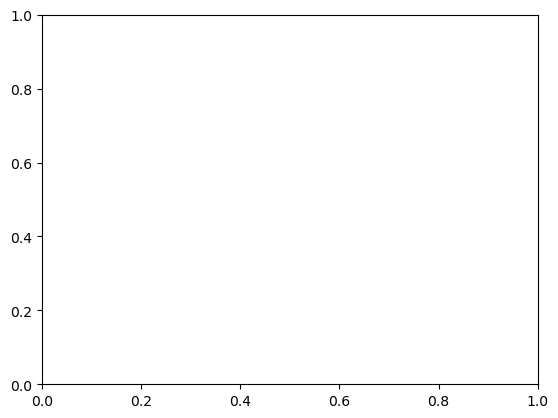

In [9]:
plt.plot(0, figsize=(16, 4), color='tab:blue', linewidth=1.5)

In [ ]:
from pmdarima import auto_arima

# Si pmdarima no está instalado, ejecuta en otra celda:
# %pip install pmdarima


# Serie de ozono
fig, ax = plt.subplots(figsize=(16, 5))
o_3.plot(ax=ax, color="tab:blue", linewidth=0.7)
ax.set(title="Concentración horaria de ozono (O₃)", xlabel="Fecha", ylabel="O₃ (µg/m³)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# División temporal: 80 % entrenamiento y 20 % prueba
corte = int(len(o_3) * 0.8)
train, test = o_3.iloc[:corte], o_3.iloc[corte:]

# Selección automática del orden ARIMA (sin componente estacional)
modelo_arima = auto_arima(
    train,
    seasonal=False,
    stepwise=True,
    max_p=5,
    max_q=5,
    information_criterion="aic",
    suppress_warnings=True,
    error_action="ignore",
    trace=True
)

print(f"Orden seleccionado: ARIMA{modelo_arima.order}")

# Pronóstico para el período de prueba
pronostico = pd.Series(
    modelo_arima.predict(n_periods=len(test)),
    index=test.index,
    name="Pronóstico"
)

# Evaluación
print(f"MAE : {mean_absolute_error(test, pronostico):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(test, pronostico)):.2f}")

# Comparación visual
fig, ax = plt.subplots(figsize=(16, 5))
train.iloc[-24 * 7:].plot(ax=ax, label="Entrenamiento (última semana)")
test.plot(ax=ax, label="Observado", color="tab:blue", alpha=0.8)
pronostico.plot(ax=ax, label="Pronóstico ARIMA", color="tab:red")
ax.set(title="Pronóstico de ozono con ARIMA automático", xlabel="Fecha", ylabel="O₃ (µg/m³)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()